In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.impute import SimpleImputer

from sklearn.compose import ColumnTransformer

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.svm import SVC

from sklearn.ensemble import (
    RandomForestClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier,
    BaggingClassifier
)
from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

# Change these two values
df = pd.read_csv("stock_data.csv")

print(df.head())
print(df.shape)
print(df.isnull().sum())
print(df["Target"].value_counts())

       Open     Close      High       Low    Volume       RSI      MACD  \
0  0.374639  0.374780  0.373510  0.378390  0.298909  0.847286  0.741715   
1  0.950982  0.937746  0.938422  0.946158  0.094805  0.494543  0.881343   
2  0.732198  0.719825  0.723644  0.723158  0.126348  0.195471  0.463179   
3  0.598823  0.599865  0.596973  0.605322  0.180662  0.736684  0.289076   
4  0.156053  0.163410  0.155891  0.166084  0.203646  0.418698  0.318761   

   Bollinger_Upper  Bollinger_Lower  Sentiment_Score  GDP_Growth  \
0         0.367146         0.366420         0.877177    0.580868   
1         0.938396         0.935640         0.907192    0.527044   
2         0.710666         0.702300         0.378363    0.351052   
3         0.593793         0.586936         0.231614    0.493274   
4         0.164158         0.156355         0.191642    0.365116   

   Inflation_Rate  Target  
0        0.038604       0  
1        0.108908       0  
2        0.432540       0  
3        0.946349       0  


In [3]:
# Remove rows with missing target labels
df = df.dropna(subset=["Target"]).copy()

X = df.drop(columns=["Target"])
y = df["Target"]

# Encode target labels
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y)

# Identify feature types
numeric_cols = X.select_dtypes(include=np.number).columns.tolist()
categorical_cols = X.select_dtypes(exclude=np.number).columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Numerical preprocessing
num_imputer = SimpleImputer(strategy="median")
X_train_num = num_imputer.fit_transform(X_train[numeric_cols])
X_test_num = num_imputer.transform(X_test[numeric_cols])

scaler = StandardScaler()
X_train_num = scaler.fit_transform(X_train_num)
X_test_num = scaler.transform(X_test_num)

# Categorical preprocessing
if categorical_cols:
    cat_imputer = SimpleImputer(strategy="most_frequent")
    X_train_cat = cat_imputer.fit_transform(X_train[categorical_cols])
    X_test_cat = cat_imputer.transform(X_test[categorical_cols])

    encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    X_train_cat = encoder.fit_transform(X_train_cat)
    X_test_cat = encoder.transform(X_test_cat)

    X_train_scaled = np.hstack([X_train_num, X_train_cat])
    X_test_scaled = np.hstack([X_test_num, X_test_cat])
else:
    X_train_scaled = X_train_num
    X_test_scaled = X_test_num

class_labels = np.arange(len(label_encoder.classes_))

print("Training shape:", X_train_scaled.shape)
print("Testing shape:", X_test_scaled.shape)
print("Classes:", label_encoder.classes_)

Training shape: (8000, 12)
Testing shape: (2000, 12)
Classes: [0 1]


In [4]:
results = []
trained_models = {}
predictions = {}

def evaluate_model(name, model):
    model.fit(X_train_scaled, y_train)

    y_pred = model.predict(X_test_scaled)
    y_prob = model.predict_proba(X_test_scaled)

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(
        y_test, y_pred, average="weighted", zero_division=0
    )
    recall = recall_score(
        y_test, y_pred, average="weighted", zero_division=0
    )
    weighted_f1 = f1_score(
        y_test, y_pred, average="weighted", zero_division=0
    )

    # ROC-AUC
    try:
        if len(class_labels) == 2:
            roc_auc = roc_auc_score(y_test, y_prob[:, 1])
        else:
            roc_auc = roc_auc_score(
                y_test,
                y_prob,
                labels=class_labels,
                multi_class="ovr",
                average="weighted"
            )
    except ValueError:
        roc_auc = np.nan

    cm = confusion_matrix(y_test, y_pred, labels=class_labels)

    print("\n")
    print(name)
   
    print("Accuracy:", round(accuracy, 4))
    print("Precision (weighted):", round(precision, 4))
    print("Recall (weighted):", round(recall, 4))
    print("F1-score (weighted):", round(weighted_f1, 4))
    print("ROC-AUC:", round(roc_auc, 4) if not np.isnan(roc_auc) else "Undefined")

    print("\nClassification Report:")
    print(classification_report(
        y_test, y_pred,
        labels=class_labels,
        target_names=[str(c) for c in label_encoder.classes_],
        zero_division=0
    ))

    plt.figure(figsize=(6, 4))
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=label_encoder.classes_,
        yticklabels=label_encoder.classes_
    )
    plt.title(f"{name} - Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.tight_layout()
    plt.show()

    results.append({
        "Algorithm": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "Weighted F1": weighted_f1,
        "ROC-AUC": roc_auc
    })

    trained_models[name] = model
    predictions[name] = y_pred

    return model



Logistic Regression
Accuracy: 0.942
Precision (weighted): 0.9454
Recall (weighted): 0.942
F1-score (weighted): 0.9153
ROC-AUC: 0.9437

Classification Report:
              precision    recall  f1-score   support

           0       0.94      1.00      0.97      1881
           1       1.00      0.03      0.05       119

    accuracy                           0.94      2000
   macro avg       0.97      0.51      0.51      2000
weighted avg       0.95      0.94      0.92      2000



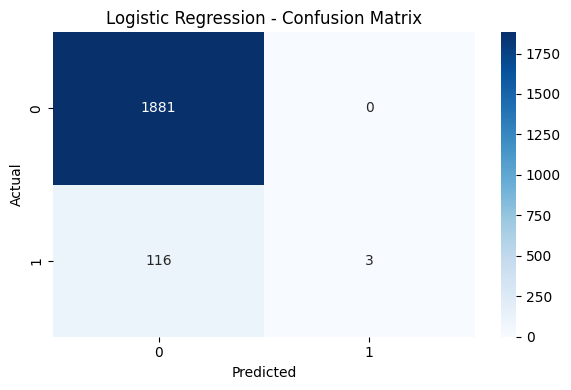



KNN
Accuracy: 0.9285
Precision (weighted): 0.9016
Recall (weighted): 0.9285
F1-score (weighted): 0.9127
ROC-AUC: 0.7573

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.98      0.96      1881
           1       0.23      0.08      0.12       119

    accuracy                           0.93      2000
   macro avg       0.59      0.53      0.54      2000
weighted avg       0.90      0.93      0.91      2000



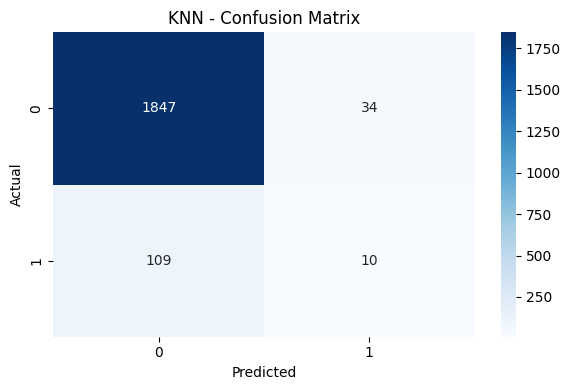



Naive Bayes
Accuracy: 0.787
Precision (weighted): 0.9486
Recall (weighted): 0.787
F1-score (weighted): 0.8414
ROC-AUC: 0.899

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.78      0.87      1881
           1       0.21      0.94      0.34       119

    accuracy                           0.79      2000
   macro avg       0.60      0.86      0.61      2000
weighted avg       0.95      0.79      0.84      2000



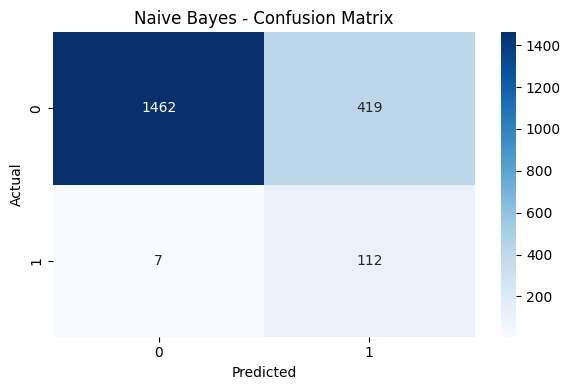



Decision Tree
Accuracy: 0.956
Precision (weighted): 0.9547
Recall (weighted): 0.956
F1-score (weighted): 0.9553
ROC-AUC: 0.7877

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.98      0.98      1881
           1       0.64      0.60      0.62       119

    accuracy                           0.96      2000
   macro avg       0.81      0.79      0.80      2000
weighted avg       0.95      0.96      0.96      2000



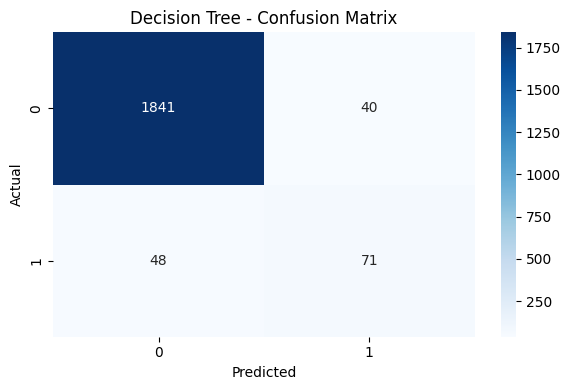

c:\Users\LENOVO\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(




SVM
Accuracy: 0.9405
Precision (weighted): 0.8845
Recall (weighted): 0.9405
F1-score (weighted): 0.9117
ROC-AUC: 0.9694

Classification Report:
              precision    recall  f1-score   support

           0       0.94      1.00      0.97      1881
           1       0.00      0.00      0.00       119

    accuracy                           0.94      2000
   macro avg       0.47      0.50      0.48      2000
weighted avg       0.88      0.94      0.91      2000



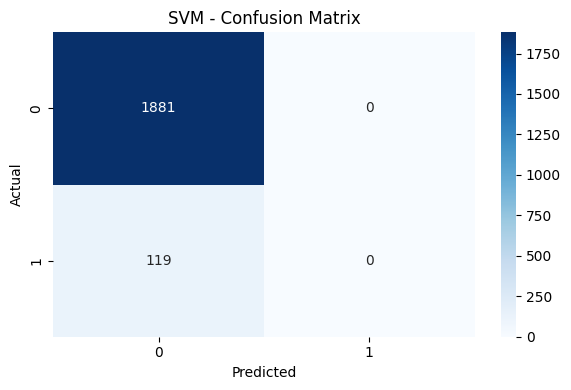

In [5]:
# 1. Logistic Regression
lr_model = evaluate_model(
    "Logistic Regression",
    LogisticRegression(max_iter=2000, random_state=42)
)

# 2. K-Nearest Neighbors
knn_model = evaluate_model(
    "KNN",
    KNeighborsClassifier(n_neighbors=5, metric="minkowski")
)

# 3. Naive Bayes (Gaussian)
nb_model = evaluate_model(
    "Naive Bayes",
    GaussianNB()
)

# 4. Decision Tree
dt_model = evaluate_model(
    "Decision Tree",
    DecisionTreeClassifier(max_depth=None, random_state=42)
)

# 5. Support Vector Machine
svm_model = evaluate_model(
    "SVM",
    SVC(C=1.0, kernel="rbf", probability=True, random_state=42)
)



Random Forest
Accuracy: 0.9595
Precision (weighted): 0.9601
Recall (weighted): 0.9595
F1-score (weighted): 0.9499
ROC-AUC: 0.9673

Classification Report:
              precision    recall  f1-score   support

           0       0.96      1.00      0.98      1881
           1       0.97      0.33      0.49       119

    accuracy                           0.96      2000
   macro avg       0.97      0.66      0.73      2000
weighted avg       0.96      0.96      0.95      2000



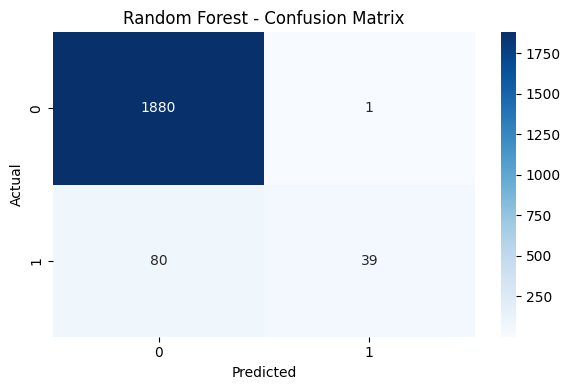

In [6]:
# 6. Random Forest
rf_model = evaluate_model(
    "Random Forest",
    RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )
)




AdaBoost
Accuracy: 0.9405
Precision (weighted): 0.8845
Recall (weighted): 0.9405
F1-score (weighted): 0.9117
ROC-AUC: 0.8931

Classification Report:
              precision    recall  f1-score   support

           0       0.94      1.00      0.97      1881
           1       0.00      0.00      0.00       119

    accuracy                           0.94      2000
   macro avg       0.47      0.50      0.48      2000
weighted avg       0.88      0.94      0.91      2000



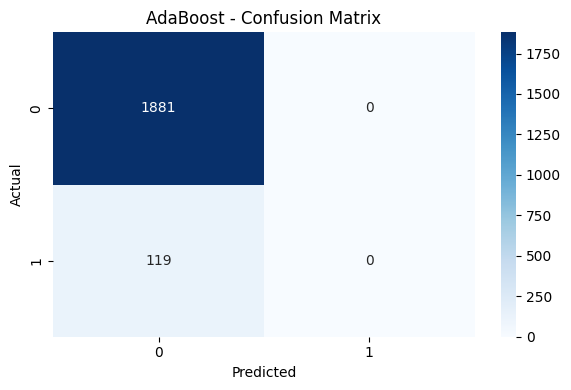

In [7]:
# 7. AdaBoost
ada_model = evaluate_model(
    "AdaBoost",
    AdaBoostClassifier(
        n_estimators=50,
        learning_rate=1.0,
        random_state=42
    )
)




Gradient Boosting
Accuracy: 0.9605
Precision (weighted): 0.9584
Recall (weighted): 0.9605
F1-score (weighted): 0.9528
ROC-AUC: 0.9629

Classification Report:
              precision    recall  f1-score   support

           0       0.96      1.00      0.98      1881
           1       0.90      0.38      0.53       119

    accuracy                           0.96      2000
   macro avg       0.93      0.69      0.76      2000
weighted avg       0.96      0.96      0.95      2000



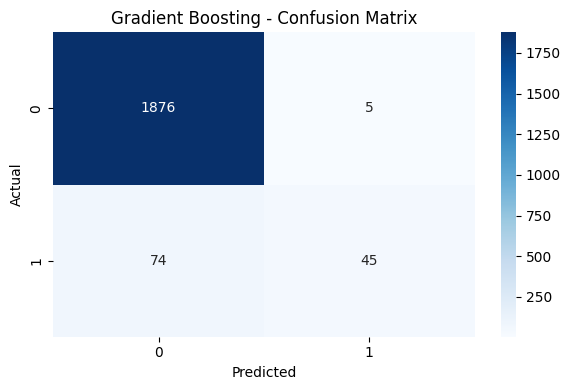

In [8]:
# 8. Gradient Boosting
gb_model = evaluate_model(
    "Gradient Boosting",
    GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    )
)



Bagging
Accuracy: 0.971
Precision (weighted): 0.9702
Recall (weighted): 0.971
F1-score (weighted): 0.9673
ROC-AUC: 0.975

Classification Report:
              precision    recall  f1-score   support

           0       0.97      1.00      0.98      1881
           1       0.94      0.55      0.69       119

    accuracy                           0.97      2000
   macro avg       0.96      0.77      0.84      2000
weighted avg       0.97      0.97      0.97      2000



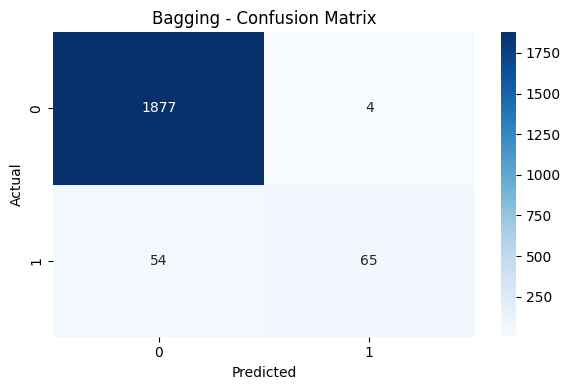

In [9]:
# 9. Bagging with Decision Tree as base estimator
bag_model = evaluate_model(
    "Bagging",
    BaggingClassifier(
        estimator=DecisionTreeClassifier(random_state=42),
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )
)



MLP Neural Network
Accuracy: 0.9405
Precision (weighted): 0.8845
Recall (weighted): 0.9405
F1-score (weighted): 0.9117
ROC-AUC: 0.4737

Classification Report:
              precision    recall  f1-score   support

           0       0.94      1.00      0.97      1881
           1       0.00      0.00      0.00       119

    accuracy                           0.94      2000
   macro avg       0.47      0.50      0.48      2000
weighted avg       0.88      0.94      0.91      2000



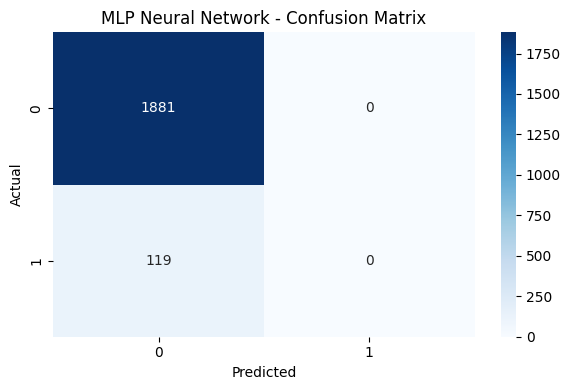

In [10]:
# 10. MLP Neural Network
mlp_model = evaluate_model(
    "MLP Neural Network",
    MLPClassifier(
        hidden_layer_sizes=(100,),
        activation="relu",
        max_iter=500,
        early_stopping=True,
        random_state=42
    )
)

,Feature,Importance
0,Open,0.180933
1,Close,0.142807
3,Low,0.106178
2,High,0.101975
8,Bollinger_Lower,0.086374
7,Bollinger_Upper,0.083839
11,Inflation_Rate,0.052362
6,MACD,0.051401
5,RSI,0.051318
9,Sentiment_Score,0.051031


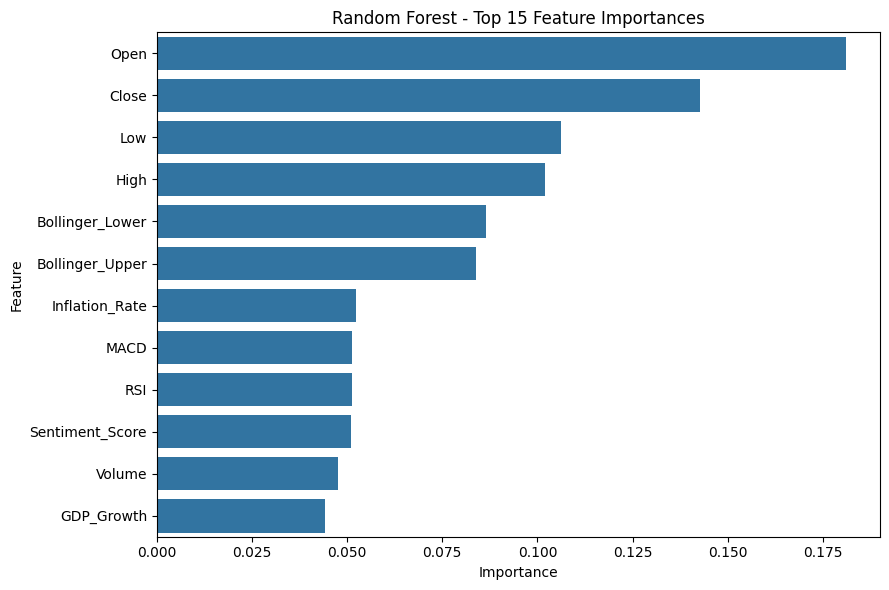

In [11]:
# Get transformed feature names
feature_names = list(numeric_cols)

if categorical_cols:
    feature_names += list(encoder.get_feature_names_out(categorical_cols))

rf_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_model.feature_importances_
}).sort_values("Importance", ascending=False)

display(rf_importance)

plt.figure(figsize=(9, 6))
sns.barplot(
    data=rf_importance.head(15),
    x="Importance",
    y="Feature"
)
plt.title("Random Forest - Top 15 Feature Importances")
plt.tight_layout()
plt.show()

In [12]:
from sklearn.base import clone

# Save baseline weighted F1 scores
baseline_f1 = {
    row["Algorithm"]: row["Weighted F1"]
    for row in results
}

tuning_configs = {
    "KNN": (
        KNeighborsClassifier(),
        {
            "n_neighbors": [3, 5, 7, 9],
            "weights": ["uniform", "distance"],
            "metric": ["euclidean", "manhattan"]
        }
    ),
    "Decision Tree": (
        DecisionTreeClassifier(random_state=42),
        {
            "max_depth": [None, 5, 10, 20],
            "min_samples_split": [2, 5, 10],
            "criterion": ["gini", "entropy"]
        }
    ),
    "SVM": (
        SVC(probability=True, random_state=42),
        {
            "C": [0.1, 1, 10],
            "kernel": ["linear", "rbf"],
            "gamma": ["scale", "auto"]
        }
    ),
    "Random Forest": (
        RandomForestClassifier(random_state=42, n_jobs=-1),
        {
            "n_estimators": [100, 200],
            "max_depth": [None, 10, 20],
            "min_samples_split": [2, 5]
        }
    ),
    "AdaBoost": (
        AdaBoostClassifier(random_state=42),
        {
            "n_estimators": [50, 100, 200],
            "learning_rate": [0.01, 0.1, 1.0]
        }
    ),
    "MLP Neural Network": (
        MLPClassifier(
            max_iter=500,
            early_stopping=True,
            random_state=42
        ),
        {
            "hidden_layer_sizes": [(50,), (100,), (100, 50)],
            "activation": ["relu", "tanh"],
            "alpha": [0.0001, 0.001]
        }
    )
}

tuned_models = {}
tuning_rows = []

for name, (estimator, param_grid) in tuning_configs.items():
    print("Tuning:", name)

    search = GridSearchCV(
        estimator=estimator,
        param_grid=param_grid,
        scoring="f1_weighted",
        cv=3,
        n_jobs=-1,
        refit=True
    )

    search.fit(X_train_scaled, y_train)
    tuned_models[name] = search.best_estimator_

    # Evaluate the tuned model on the same held-out test set
    y_pred_tuned = search.best_estimator_.predict(X_test_scaled)
    y_prob_tuned = search.best_estimator_.predict_proba(X_test_scaled)

    tuned_f1 = f1_score(
        y_test, y_pred_tuned,
        average="weighted",
        zero_division=0
    )

    if len(class_labels) == 2:
        tuned_auc = roc_auc_score(y_test, y_prob_tuned[:, 1])
    else:
        try:
            tuned_auc = roc_auc_score(
                y_test,
                y_prob_tuned,
                labels=class_labels,
                multi_class="ovr",
                average="weighted"
            )
        except ValueError:
            tuned_auc = np.nan

    old_f1 = baseline_f1[name]

    tuning_rows.append({
        "Algorithm": name,
        "Baseline Weighted F1": old_f1,
        "Tuned Weighted F1": tuned_f1,
        "F1 Improvement": tuned_f1 - old_f1,
        "Best Parameters": search.best_params_,
        "ROC-AUC After Tuning": tuned_auc
    })

    print("Best parameters:", search.best_params_)
    print("CV weighted F1:", round(search.best_score_, 4))
    print("Test weighted F1 before:", round(old_f1, 4))
    print("Test weighted F1 after:", round(tuned_f1, 4))
    print("Improvement:", round(tuned_f1 - old_f1, 4))
    print("-" * 50)

tuning_comparison = pd.DataFrame(tuning_rows)
display(tuning_comparison)

Tuning: KNN
Best parameters: {'metric': 'manhattan', 'n_neighbors': 5, 'weights': 'uniform'}
CV weighted F1: 0.9136
Test weighted F1 before: 0.9127
Test weighted F1 after: 0.917
Improvement: 0.0043
--------------------------------------------------
Tuning: Decision Tree
Best parameters: {'criterion': 'entropy', 'max_depth': None, 'min_samples_split': 2}
CV weighted F1: 0.9535
Test weighted F1 before: 0.9553
Test weighted F1 after: 0.9657
Improvement: 0.0104
--------------------------------------------------
Tuning: SVM


c:\Users\LENOVO\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Best parameters: {'C': 10, 'gamma': 'scale', 'kernel': 'linear'}
CV weighted F1: 0.9696
Test weighted F1 before: 0.9117
Test weighted F1 after: 0.9796
Improvement: 0.0679
--------------------------------------------------
Tuning: Random Forest
Best parameters: {'max_depth': None, 'min_samples_split': 5, 'n_estimators': 200}
CV weighted F1: 0.9335
Test weighted F1 before: 0.9499
Test weighted F1 after: 0.9553
Improvement: 0.0055
--------------------------------------------------
Tuning: AdaBoost
Best parameters: {'learning_rate': 1.0, 'n_estimators': 200}
CV weighted F1: 0.9123
Test weighted F1 before: 0.9117
Test weighted F1 after: 0.9117
Improvement: 0.0
--------------------------------------------------
Tuning: MLP Neural Network
Best parameters: {'activation': 'tanh', 'alpha': 0.0001, 'hidden_layer_sizes': (50,)}
CV weighted F1: 0.9118
Test weighted F1 before: 0.9117
Test weighted F1 after: 0.9117
Improvement: 0.0
--------------------------------------------------


,Algorithm,Baseline Weighted F1,Tuned Weighted F1,F1 Improvement,Best Parameters,ROC-AUC After Tuning
0,KNN,0.912749,0.917029,0.004280,"{'metric': 'manhattan', 'n_neighbors': 5, 'wei...",0.745551
1,Decision Tree,0.955281,0.965727,0.010446,"{'criterion': 'entropy', 'max_depth': None, 'm...",0.840233
2,SVM,0.911662,0.979604,0.067942,"{'C': 10, 'gamma': 'scale', 'kernel': 'linear'}",0.996497
3,Random Forest,0.949855,0.955323,0.005468,"{'max_depth': None, 'min_samples_split': 5, 'n...",0.973662
4,AdaBoost,0.911662,0.911662,0.000000,"{'learning_rate': 1.0, 'n_estimators': 200}",0.907900
5,MLP Neural Network,0.911662,0.911662,0.000000,"{'activation': 'tanh', 'alpha': 0.0001, 'hidde...",0.875451


In [13]:
# FINAL CONSOLIDATED TABLE — ALL 10 ALGORITHMS

comparison = pd.DataFrame(results)

# Confirm that all ten required algorithms are present
print("Number of algorithms:", comparison["Algorithm"].nunique())
display(comparison.round(4))


Number of algorithms: 10


,Algorithm,Accuracy,Precision,Recall,Weighted F1,ROC-AUC
0,Logistic Regression,0.9420,0.9454,0.9420,0.9153,0.9437
1,KNN,0.9285,0.9016,0.9285,0.9127,0.7573
2,Naive Bayes,0.7870,0.9486,0.7870,0.8414,0.8990
3,Decision Tree,0.9560,0.9547,0.9560,0.9553,0.7877
4,SVM,0.9405,0.8845,0.9405,0.9117,0.9694
5,Random Forest,0.9595,0.9601,0.9595,0.9499,0.9673
6,AdaBoost,0.9405,0.8845,0.9405,0.9117,0.8931
7,Gradient Boosting,0.9605,0.9584,0.9605,0.9528,0.9629
8,Bagging,0.9710,0.9702,0.9710,0.9673,0.9750
9,MLP Neural Network,0.9405,0.8845,0.9405,0.9117,0.4737


In [14]:
# FINAL MODEL SELECTION

best_row = comparison.loc[comparison["Weighted F1"].idxmax()]
best_name = best_row["Algorithm"]
best_model = trained_models[best_name]

print("Best baseline model:", best_name)
print("Accuracy:", round(best_row["Accuracy"], 4))
print("Precision:", round(best_row["Precision"], 4))
print("Recall:", round(best_row["Recall"], 4))
print("Weighted F1:", round(best_row["Weighted F1"], 4))
print("ROC-AUC:", round(best_row["ROC-AUC"], 4))

print("\nJustification:")
print(
    f"{best_name} achieved the highest weighted F1-score among "
    "the ten baseline classifiers. Its accuracy, recall, ROC-AUC, "
    "and confusion matrix should also be considered when assessing "
    "its performance across all classes."
)

Best baseline model: Bagging
Accuracy: 0.971
Precision: 0.9702
Recall: 0.971
Weighted F1: 0.9673
ROC-AUC: 0.975

Justification:
Bagging achieved the highest weighted F1-score among the ten baseline classifiers. Its accuracy, recall, ROC-AUC, and confusion matrix should also be considered when assessing its performance across all classes.


In [15]:
# Compare all 10 classification algorithms

comparison = pd.DataFrame(results)

comparison = comparison.sort_values(
    by="Weighted F1",
    ascending=False
).reset_index(drop=True)

display(comparison.round(4))

,Algorithm,Accuracy,Precision,Recall,Weighted F1,ROC-AUC
0,Bagging,0.9710,0.9702,0.9710,0.9673,0.9750
1,Decision Tree,0.9560,0.9547,0.9560,0.9553,0.7877
2,Gradient Boosting,0.9605,0.9584,0.9605,0.9528,0.9629
3,Random Forest,0.9595,0.9601,0.9595,0.9499,0.9673
4,Logistic Regression,0.9420,0.9454,0.9420,0.9153,0.9437
5,KNN,0.9285,0.9016,0.9285,0.9127,0.7573
6,AdaBoost,0.9405,0.8845,0.9405,0.9117,0.8931
7,SVM,0.9405,0.8845,0.9405,0.9117,0.9694
8,MLP Neural Network,0.9405,0.8845,0.9405,0.9117,0.4737
9,Naive Bayes,0.7870,0.9486,0.7870,0.8414,0.8990


In [16]:
part_b_names = [
    "Random Forest",
    "AdaBoost",
    "Gradient Boosting",
    "Bagging",
    "MLP Neural Network"
]

part_b_comparison = comparison[
    comparison["Algorithm"].isin(part_b_names)
]

display(part_b_comparison.round(4))

,Algorithm,Accuracy,Precision,Recall,Weighted F1,ROC-AUC
0,Bagging,0.9710,0.9702,0.9710,0.9673,0.9750
2,Gradient Boosting,0.9605,0.9584,0.9605,0.9528,0.9629
3,Random Forest,0.9595,0.9601,0.9595,0.9499,0.9673
6,AdaBoost,0.9405,0.8845,0.9405,0.9117,0.8931
8,MLP Neural Network,0.9405,0.8845,0.9405,0.9117,0.4737


In [17]:
tuning_comparison = pd.DataFrame(tuning_rows)

display(
    tuning_comparison[
        [
            "Algorithm",
            "Baseline Weighted F1",
            "Tuned Weighted F1",
            "F1 Improvement",
            "Best Parameters",
            "ROC-AUC After Tuning"
        ]
    ].round(4)
)

,Algorithm,Baseline Weighted F1,Tuned Weighted F1,F1 Improvement,Best Parameters,ROC-AUC After Tuning
0,KNN,0.9127,0.9170,0.0043,"{'metric': 'manhattan', 'n_neighbors': 5, 'wei...",0.7456
1,Decision Tree,0.9553,0.9657,0.0104,"{'criterion': 'entropy', 'max_depth': None, 'm...",0.8402
2,SVM,0.9117,0.9796,0.0679,"{'C': 10, 'gamma': 'scale', 'kernel': 'linear'}",0.9965
3,Random Forest,0.9499,0.9553,0.0055,"{'max_depth': None, 'min_samples_split': 5, 'n...",0.9737
4,AdaBoost,0.9117,0.9117,0.0000,"{'learning_rate': 1.0, 'n_estimators': 200}",0.9079
5,MLP Neural Network,0.9117,0.9117,0.0000,"{'activation': 'tanh', 'alpha': 0.0001, 'hidde...",0.8755


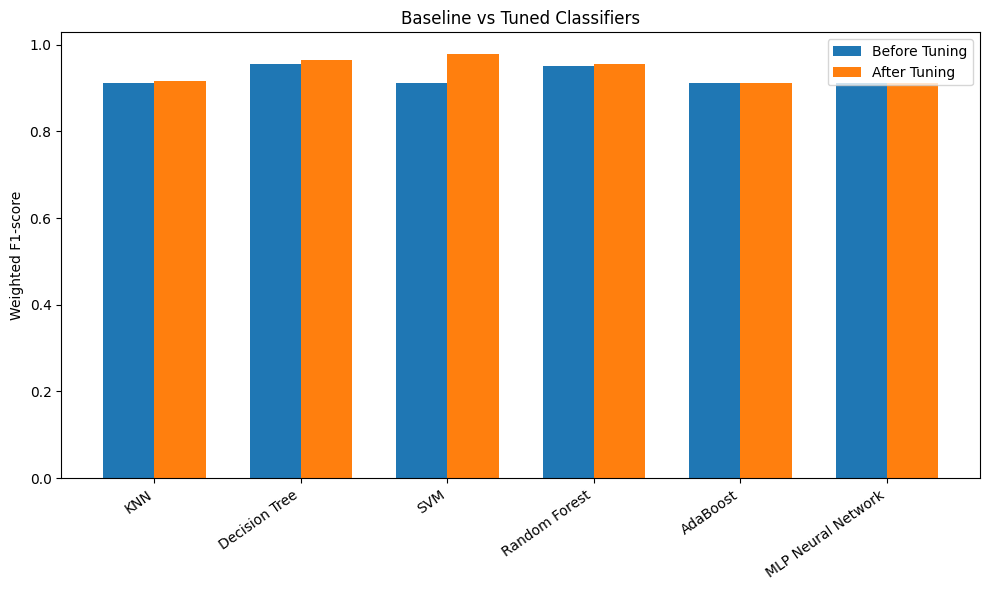

In [18]:
plt.figure(figsize=(10, 6))

x = np.arange(len(tuning_comparison))
width = 0.35

plt.bar(
    x - width / 2,
    tuning_comparison["Baseline Weighted F1"],
    width,
    label="Before Tuning"
)

plt.bar(
    x + width / 2,
    tuning_comparison["Tuned Weighted F1"],
    width,
    label="After Tuning"
)

plt.xticks(
    x,
    tuning_comparison["Algorithm"],
    rotation=35,
    ha="right"
)

plt.ylabel("Weighted F1-score")
plt.title("Baseline vs Tuned Classifiers")
plt.legend()
plt.tight_layout()
plt.show()

In [19]:
best_row = comparison.loc[
    comparison["Weighted F1"].idxmax()
]

print("BEST BASELINE MODEL:", best_row["Algorithm"])
print("Accuracy:", round(best_row["Accuracy"], 4))
print("Precision:", round(best_row["Precision"], 4))
print("Recall:", round(best_row["Recall"], 4))
print("Weighted F1:", round(best_row["Weighted F1"], 4))
print("ROC-AUC:", round(best_row["ROC-AUC"], 4))

print("\nJUSTIFICATION:")
print(
    f"{best_row['Algorithm']} achieved the highest weighted F1-score "
    "among the ten baseline classifiers. Its confusion matrix, recall, "
    "ROC-AUC, and performance on minority classes should also be "
    "considered before making the final selection."
)

BEST BASELINE MODEL: Bagging
Accuracy: 0.971
Precision: 0.9702
Recall: 0.971
Weighted F1: 0.9673
ROC-AUC: 0.975

JUSTIFICATION:
Bagging achieved the highest weighted F1-score among the ten baseline classifiers. Its confusion matrix, recall, ROC-AUC, and performance on minority classes should also be considered before making the final selection.
